# MDD local — setup, demo, visualization và kiểm thử so sánh

<!-- verified-test-summary:start -->
## Kết quả test đã hoàn tất — fold 1

**150 câu HQTV · seed 42 · best checkpoint chọn bằng validation.**

| Mô hình | Precision (%) | Recall (%) | F1 phát hiện lỗi (%) ↑ | PER (%) ↓ |
|---|---:|---:|---:|---:|
| A — source | 67,77 | 65,02 | 66,37 | 21,39 |
| B — thích ứng tiếng Việt | 70,29 | 71,43 | 70,85 | 19,25 |
| C — đối chứng source | 67,27 | 63,25 | 65,20 | 21,99 |

B đạt F1 **70,85%**, cao hơn A **4,49 điểm phần trăm** và cao hơn C **5,66 điểm phần trăm**.
B có PER thấp nhất trong ba model ở phép đánh giá này. Đây là kết quả một fold / một người nói test; chưa phải tổng hợp bốn fold.

Các mục 24, 29 và 30 bên dưới đã có learning curves, biểu đồ test/delta và heatmap lỗi từ kết quả thật.
<!-- verified-test-summary:end -->

Chạy từng cell từ trên xuống bằng **Shift+Enter**, hoặc **Run All** để chạy quy trình đã cấu hình.
**A/B/C đã train hoàn tất**. Notebook đánh giá best checkpoint trên test fold 1 và hiển thị
bảng/biểu đồ so sánh thật; các run đã hoàn tất được giữ nguyên khi chạy lại.
Chọn kernel **MDD (.venv)**. Notebook dùng protocol `l2arctic-v1` và code thật của dự án.

Mỗi thao tác có cell riêng: kiểm tra môi trường → dữ liệu/split → nghe audio và xem phổ →
BASE/phoneme inference → kiểm thử → train smoke/A/B/C → learning curves → test → so sánh.
Hình PNG, bảng CSV, JSON và log lệnh được lưu trong `data/generated/notebook/<session>/`.

**Trạng thái kết quả:** checkpoint smoke chỉ kiểm tra kỹ thuật. Điểm của smoke và ví dụ
thuật toán không chứng minh chất lượng MDD. Biểu đồ A/B/C chỉ xuất hiện sau khi có đủ
ba lượt train khoa học và đánh giá test hợp lệ; notebook không tạo điểm giả khi thiếu dữ liệu.
Demo lấy audio từ source train. Gold label chỉ dùng để minh họa annotation hoặc chấm sau inference.


## 1. Lệnh setup và mở notebook (PowerShell, tại thư mục project)

```powershell
pwsh -File scripts/setup_notebook.ps1
pwsh -File scripts/run_notebook.ps1 -OpenBrowser
```

Máy hiện tại đã có `.venv`, BASE và dữ liệu. Với máy Windows NVIDIA mới, chạy thêm
`pwsh -File scripts/setup_local_training.ps1` **trước** setup notebook.
Kiểm tra lại môi trường notebook không cần mạng: `pwsh -File scripts/setup_notebook.ps1 -Offline`.
Nếu cổng bận, dùng `pwsh -File scripts/run_notebook.ps1 -Port 8890 -OpenBrowser`.
Trong Jupyter chọn `notebooks/mdd_local_demo_comparison.ipynb`; **Ctrl+S** lưu cả output vào file.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib.metadata
import json
import os
import subprocess
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/mdd/runtime.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Mở Jupyter từ thư mục project MDD.")
PYTHON = ROOT / (".venv/Scripts/python.exe" if os.name == "nt" else ".venv/bin/python")
if Path(sys.executable).resolve() != PYTHON.resolve():
    raise RuntimeError(f"Chọn kernel MDD (.venv). Python cần dùng: {PYTHON}")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))
os.environ.update(HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1",
                  TOKENIZERS_PARALLELISM="false", PYTHONIOENCODING="utf-8", PYTHONUTF8="1",
                  OMP_NUM_THREADS="2", MKL_NUM_THREADS="2")
SESSION = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT = ROOT / "data/generated/notebook" / SESSION
OUT.mkdir(parents=True, exist_ok=False)
os.environ["MPLCONFIGDIR"] = str(ROOT / ".venv/matplotlib")
print("Project:", ROOT)
print("Python:", sys.executable)
print("Output:", OUT)


Project: D:\NCC\MDD
Python: D:\NCC\MDD\.venv\Scripts\python.exe
Output: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z


## 2. Tham số của phiên chạy thật

`RUN_TRAIN_A/B/C=True`: A chạy 2.000 updates, B/C mỗi lượt 400 updates, khởi tạo từ
cùng best checkpoint A. A/B/C đã train hoàn tất; `RUN_FINAL_TEST=True` đánh giá các best checkpoint trên toàn bộ test fold 1.
Smoke vẫn tắt. Các run hoàn tất được giữ nguyên, không train lại.
Cell train nhận biết PID của chuỗi nền và hiển thị tiến độ thay vì mở tiến trình trùng.
Sau khi chuỗi hoàn tất, chạy lại cell learning curves để cập nhật biểu đồ từ log thật.


In [2]:
import torch

FOLD = 1
SEED = 42
TRAIN_DEVICE = "cuda"
if not torch.cuda.is_available():
    raise RuntimeError("Train thật cần CUDA; kiểm tra driver và .venv trước khi bắt đầu.")
PRESET = "windows"
EXPERIMENT = f"{PRESET}-notebook-seed{SEED}"
RUN_SMOKE_TRAIN = False
RUN_TRAIN_A = True
RUN_TRAIN_B = True
RUN_TRAIN_C = True
RUN_FINAL_TEST = True
RESUME_STAGE = None  # Đổi thành "A", "B" hoặc "C" khi cần resume; bật RUN_RESUME.
RUN_RESUME = False

RUN_IDS = {"A": f"{EXPERIMENT}-A", "B": f"{EXPERIMENT}-B-fold{FOLD}",
           "C": f"{EXPERIMENT}-C-fold{FOLD}"}
CHECKPOINTS = {stage: ROOT / "runs" / run_id / "best_checkpoint"
               for stage, run_id in RUN_IDS.items()}
EVALUATIONS = {stage: ROOT / "runs" / f"{run_id}-test-fold{FOLD}"
               for stage, run_id in RUN_IDS.items()}
SEQUENCE_DIR = ROOT / "data/generated/training" / f"{EXPERIMENT}-fold{FOLD}"
assert FOLD in (1, 2, 3, 4)
print("Thiết bị train/test:", TRAIN_DEVICE, "| fold:", FOLD)
print(json.dumps(RUN_IDS, indent=2))


Thiết bị train/test: cuda | fold: 1
{
  "A": "windows-notebook-seed42-A",
  "B": "windows-notebook-seed42-B-fold1",
  "C": "windows-notebook-seed42-C-fold1"
}


## 3. Hàm lưu kết quả và chạy lệnh

Mọi lệnh dùng đúng Python của kernel. Log đầy đủ được lưu ra file; cell hiển thị phần
cuối của log. Với training dài, file log được ghi liên tục để có thể xem ở terminal khác.


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, FileLink, display

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.2})

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def read_jsonl(path):
    with Path(path).open(encoding="utf-8") as stream:
        return [json.loads(line) for line in stream if line.strip()]

def read_live_log(path):
    # Training appends records ending with newline; ignore only an unfinished tail.
    text = Path(path).read_text(encoding="utf-8")
    lines = text.splitlines(keepends=True)
    if lines and not lines[-1].endswith("\n"):
        lines.pop()
    return [json.loads(line) for line in lines if line.strip()]

def save_json(name, value):
    path = OUT / f"{name}.json"
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return path

def save_table(name, frame):
    frame.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")
    display(frame)

def show_figure(name, fig):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

command_history = []
def run_python(label, *arguments, execute=True):
    command = [str(PYTHON), "-X", "utf8", *map(str, arguments)]
    # PowerShell command; arguments in this notebook contain no credentials.
    print("& " + " ".join("'" + value.replace("'", "''") + "'" for value in command))
    if not execute:
        print("Chưa chạy; bật cờ tương ứng ở cell tham số để thực thi.")
        return
    log = OUT / f"{label}-{len(command_history) + 1:02d}.log"
    with log.open("w", encoding="utf-8") as stream:
        process = subprocess.Popen(command, cwd=ROOT, env=os.environ.copy(),
                                   stdout=stream, stderr=subprocess.STDOUT)
        try:
            result = process.wait()
        except KeyboardInterrupt:
            process.terminate()
            process.wait()
            raise
    command_history.append({"label": label, "command": command, "returncode": result, "log": str(log)})
    save_json("commands", command_history)
    print("\n".join(log.read_text(encoding="utf-8", errors="replace").splitlines()[-24:]))
    print("Log:", log)
    if result:
        raise RuntimeError(f"Lệnh thất bại (exit {result}); xem log {log}")

def active_training_sequence():
    import psutil
    state_path = SEQUENCE_DIR / "state.json"
    if not state_path.is_file():
        return None
    state = read_json(state_path)
    pid = state.get("pid")
    if state.get("status") == "running" and isinstance(pid, int) and psutil.pid_exists(pid):
        return state
    return None

def run_scientific_stage(stage, execute):
    state = active_training_sequence()
    if state is not None:
        print(f"Chuỗi A → B → C đang chạy nền (PID {state['pid']}); không mở thêm tiến trình.")
        print("Stage hiện tại:", state.get("current_stage"))
        log = ROOT / "runs" / RUN_IDS[stage] / "training_log.jsonl"
        rows = read_live_log(log) if log.is_file() else []
        if rows:
            print("Tiến độ", stage, ":", rows[-1]["step"], "updates; loss", rows[-1]["loss"])
        else:
            print("Stage", stage, "đang chờ lượt chạy trong chuỗi.")
        print("Log chuỗi:", SEQUENCE_DIR / "stdout.log")
        return
    directory = ROOT / "runs" / RUN_IDS[stage]
    if directory.exists():
        completed = directory / "completed.json"
        if completed.is_file() and read_json(completed).get("status") == "completed":
            print("Stage đã hoàn tất; giữ kết quả:", directory)
        else:
            print("Run đã tồn tại; xem log/kiểm tra tiến trình trước khi resume:", directory)
        return
    suffix = {"A": "source", "B": "adapt_vi", "C": "control"}[stage]
    arguments = ["-u", "scripts/train_mdd.py", "--config", f"configs/{PRESET}_{suffix}.json",
                 "--run-id", RUN_IDS[stage], "--seed", SEED, "--device", TRAIN_DEVICE]
    if stage in ("B", "C"):
        arguments += ["--fold", FOLD, "--init-checkpoint", CHECKPOINTS["A"]]
    run_python(f"train_{stage}", *arguments, execute=execute)


## 4. Kiểm tra môi trường thực tế

Probe kiểm tra PyTorch, CUDA/CPU backward, model và input cần thiết.
`False` ở readiness là lỗi setup cần xử lý trước khi train.


In [4]:
from scripts.check_training_environment import report

environment = report()
save_json("environment", environment)
package_names = ["torch", "transformers", "numpy", "pandas", "matplotlib", "jupyterlab", "ipykernel"]
save_table("package_versions", pd.DataFrame(
    {"package": name, "version": importlib.metadata.version(name)} for name in package_names))
readiness = "ready_for_local_cuda_training" if TRAIN_DEVICE == "cuda" else "ready_for_cpu_pipeline_check"
print("Readiness:", readiness, environment.get(readiness))
print("GPU:", environment.get("torch", {}).get("gpu"))
if not environment.get(readiness):
    raise RuntimeError("Input/môi trường chưa sẵn sàng; xem environment.json và script setup.")


D:\NCC\MDD\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,package,version
0,torch,2.7.1+cu126
1,transformers,4.57.6
2,numpy,2.2.6
3,pandas,2.3.3
4,matplotlib,3.11.2
5,jupyterlab,4.6.4
6,ipykernel,6.31.0


Readiness: ready_for_local_cuda_training True
GPU: {'index': 0, 'name': 'NVIDIA GeForce RTX 3050 Laptop GPU', 'total_memory_bytes': 4294508544, 'compute_capability': [8, 6], 'free_memory_bytes': 3456368640}


## 5. Xác minh BASE local

Lệnh này kiểm tra model/checksum có sẵn và không tải lại weights.


In [5]:
run_python("verify_base", "scripts/download_models.py", "--models", "wav2vec2-base", "--verify-only")


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' 'scripts/download_models.py' '--models' 'wav2vec2-base' '--verify-only'


Verified offline: wav2vec2-base, revision=0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8
Complete: 1 checkpoints; 362.7 MiB
Log: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\verify_base-01.log


## 6. Đọc dữ liệu và kiểm tra protocol

`load_records` dùng manifest/split đã khóa. Chỉ đọc audio khi đến phần demo.
Bảng split thể hiện số câu và người nói; speaker train/validation/test phải tách biệt.


In [6]:
from mdd.runtime import DEFAULTS, load_records, load_audio

config = {**DEFAULTS, **read_json(ROOT / f"configs/{PRESET}_source.json")}
records, vocab, splits = load_records(config)
data_audit = read_json(ROOT / "data/processed/l2arctic-v1/audit.json")
data = pd.DataFrame({"utterance_id": row["utterance_id"], "speaker": row["speaker_id"],
                     "language": row["native_language"], "duration_sec": row["duration_sec"],
                     "error_count": len(row["gold_error_events"])} for row in records.values())
fold = next(item for item in splits["folds"] if item["fold"] == FOLD)
groups = {"source_train": splits["source_train_ids"], "source_validation": splits["source_validation_ids"],
          "vi_train": fold["train_ids"], "vi_validation": fold["validation_ids"], "vi_test": fold["test_ids"]}
split_rows = []
for name, identifiers in groups.items():
    selected = [records[identifier] for identifier in identifiers]
    split_rows.append({"split": name, "utterances": len(selected),
                       "speakers": ", ".join(sorted({row["speaker_id"] for row in selected})),
                       "minutes": sum(row["duration_sec"] for row in selected) / 60})
save_table("split_summary", pd.DataFrame(split_rows))
print("Tổng:", len(records), "câu |", data.speaker.nunique(), "người |", len(vocab), "tokens")
print("Checksum audio đã verify:", data_audit["audio_sha256_verified"])


,split,utterances,speakers,minutes
0,source_train,2249,"ABA, ASI, BWC, EBVS, HKK, MBMPS, NCC, NJS, SVB...",136.786879
1,source_validation,750,"ERMS, HJK, LXC, RRBI, SKA",44.532911
2,vi_train,300,"THV, TLV",19.758394
3,vi_validation,150,PNV,9.527058
4,vi_test,150,HQTV,9.202271


Tổng: 3599 câu | 24 người | 83 tokens
Checksum audio đã verify: True


## 7. Kiểm thử chia dữ liệu

Audit kiểm tra tách người/audio giữa các vai trò và báo mức trùng câu mẫu.
Protocol hiện đánh giá người nói mới đọc câu trong miền đã học; không suy ra kết quả cho câu hoàn toàn mới.


In [7]:
run_python("split_audit", "scripts/audit_data_split.py", "--output", OUT / "split_audit")


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' 'scripts/audit_data_split.py' '--output' 'D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\split_audit'


Audited 3599 examples: speaker/audio disjoint, prompt overlap present; wrote D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\split_audit.{json,md}
Log: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\split_audit-02.log


## 8. Visualization dữ liệu

Phân bố ngôn ngữ, thời lượng và số lỗi từ **annotation của con người**, không phải dự đoán.


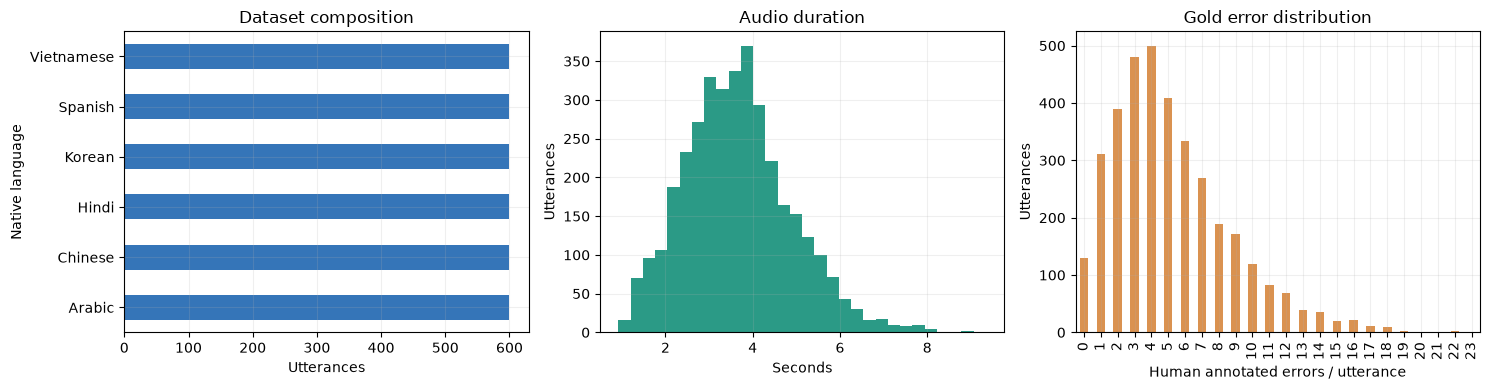

,language,utterances,speakers,minutes
0,Arabic,599,4,36.008816
1,Chinese,600,4,38.337498
2,Hindi,600,4,31.580758
3,Korean,600,4,35.434871
4,Spanish,600,4,39.957847
5,Vietnamese,600,4,38.487722


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
data.groupby("language").size().sort_values().plot.barh(ax=axes[0], color="#3575b8")
axes[0].set(xlabel="Utterances", ylabel="Native language", title="Dataset composition")
axes[1].hist(data.duration_sec, bins=30, color="#2b9a86")
axes[1].set(xlabel="Seconds", ylabel="Utterances", title="Audio duration")
data.error_count.value_counts().sort_index().plot.bar(ax=axes[2], color="#da9250")
axes[2].set(xlabel="Human annotated errors / utterance", ylabel="Utterances", title="Gold error distribution")
show_figure("dataset_overview", fig)
save_table("dataset_by_language", data.groupby("language", as_index=False).agg(
    utterances=("utterance_id", "size"), speakers=("speaker", "nunique"), minutes=("duration_sec", lambda x: x.sum()/60)))


## 9. Chọn và nghe một audio source train

Đổi `SAMPLE_INDEX` để xem mẫu khác. Các mẫu demo không lấy từ test.
`load_audio` kiểm tra checksum, gộp mono và resample toàn bộ waveform về 16 kHz.


In [9]:
from mdd.demo import DemoApplication

app = DemoApplication(ROOT, threads=2)
prompts = app.prompts()["prompts"]
if not prompts:
    raise RuntimeError("Chưa có audio source train; chạy setup/prepare dữ liệu trước.")
SAMPLE_INDEX = 0
sample_prompt = prompts[SAMPLE_INDEX]
sample_id = sample_prompt["id"]
assert sample_id in set(splits["source_train_ids"])
sample = records[sample_id]
waveform = load_audio(sample)
print(sample_id, "|", sample["native_language"], "|", sample["prompt_text"])
display(Audio(waveform, rate=16000))
save_json("sample", {"utterance_id": sample_id, "prompt_text": sample["prompt_text"],
                     "audio_sha256": sample["audio_sha256"], "source": "source_train"})


SVBI/arctic_a0117 | Hindi | She added with genuine sympathy in her face and voice


WindowsPath('D:/NCC/MDD/data/generated/notebook/20261020T153902638631Z/sample.json')

## 10. Waveform và spectrogram

Trục ngang là thời gian, trục dọc spectrogram là tần số Hz. Đây là phổ STFT,
không phải attention map hoặc đặc trưng Transformer.


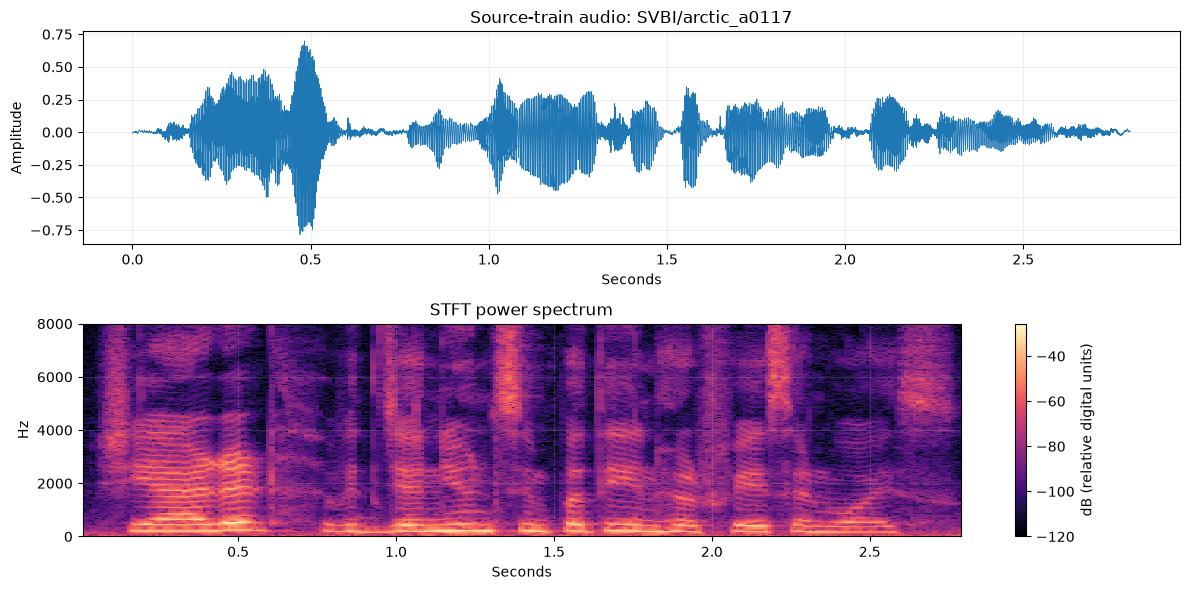

In [10]:
from scipy.signal import spectrogram

frequencies, times, power = spectrogram(waveform, fs=16000, nperseg=400, noverlap=240)
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(np.arange(len(waveform)) / 16000, waveform, linewidth=0.6)
axes[0].set(xlabel="Seconds", ylabel="Amplitude", title=f"Source-train audio: {sample_id}")
mesh = axes[1].pcolormesh(times, frequencies, 10*np.log10(np.maximum(power, 1e-12)), shading="auto", cmap="magma")
axes[1].set(xlabel="Seconds", ylabel="Hz", ylim=(0, 8000), title="STFT power spectrum")
fig.colorbar(mesh, ax=axes[1], label="dB (relative digital units)")
show_figure("audio_waveform_spectrogram", fig)


## 11. Canonical phone và perceived phone từ annotation

Canonical là âm chuẩn; perceived là âm người gán nhãn nghe được.
Màu đỏ trên waveform dùng thời gian **annotation TextGrid**. Phần này mô tả dữ liệu,
chưa chạy model hoặc xác định model đúng/sai.


Canonical: SH IY AE D IH D W IH DH JH EH N Y AH W AH N S IH M P AH TH IY IH N HH ER F EY S AH N D V OY S
Perceived (gold): SH IY AE D IH D W IH DH JH EH N Y AH AH N S IH M P AH TH IY IH N HH ER F EH S AH N W OY S


,canonical_index,end_sec,expected_phone,kind,observed_phone,perceived_index,position,raw_label,start_sec,type,word_index
0,14,1.250000,W,deletion,None,NaN,14,"W, sil, d",1.237375,deletion,3
1,29,2.180000,EY,substitution,EH,28.0,29,"EY1, EH, s",2.090000,substitution,7
2,33,2.370000,D,deletion,None,NaN,33,"D, sil, d",2.340000,deletion,8
3,34,2.433972,V,substitution,W,32.0,34,"V, W, s",2.370000,substitution,9


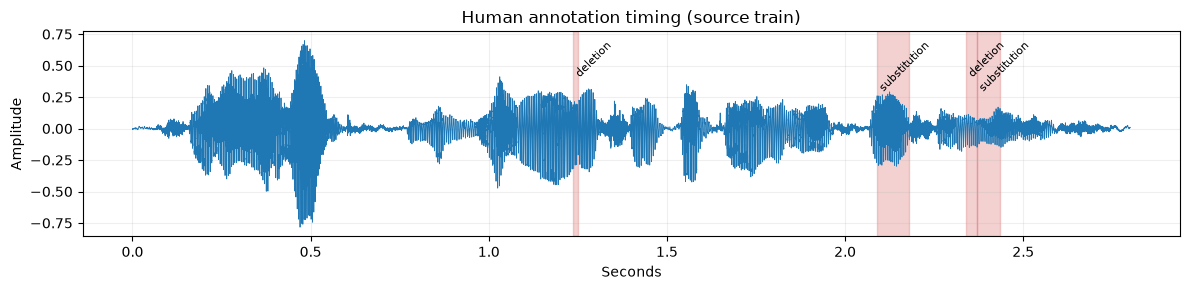

In [11]:
print("Canonical:", " ".join(sample["canonical_phones"]))
print("Perceived (gold):", " ".join(sample["perceived_phones"]))
gold_events = pd.DataFrame(sample["gold_error_events"])
save_table("sample_gold_errors", gold_events)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(len(waveform))/16000, waveform, linewidth=0.6)
for event in sample["gold_error_events"]:
    ax.axvspan(event["start_sec"], event["end_sec"], color="#d34b4b", alpha=0.25)
    ax.text(event["start_sec"], 0.96, event["kind"], rotation=45, va="top", fontsize=8,
            transform=ax.get_xaxis_transform())
ax.set(xlabel="Seconds", ylabel="Amplitude", title="Human annotation timing (source train)")
show_figure("gold_error_timing", fig)


## 12. Demo BASE: audio → đặc trưng

BASE chưa có head phoneme. Cell này chạy inference thật trên CPU và trả kích thước
đặc trưng; chưa có transcript hoặc điểm phát âm. Lần nạp weights đầu tiên có thể mất vài giây.


In [12]:
base_result = app.analyze({"model_id": "base", "reference_text": sample["prompt_text"], "sample_id": sample_id})
save_json("base_inference", base_result)
print(base_result["notice"])
display(pd.DataFrame([base_result["features"]]))
print("Thời gian gồm nạp model:", base_result["inference_seconds"], "s")


D:\NCC\MDD\.venv\Lib\site-packages\transformers\configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


Đã trích xuất đặc trưng giọng nói thực trên CPU. Chưa có điểm phát âm.


,frames,dimensions,norm_mean
0,139,768,8.572582


Thời gian gồm nạp model: 0.516 s


## 13. Demo checkpoint local: audio → phoneme CTC

Chọn `MODEL_ID` trong bảng. Mặc định dùng checkpoint tốt nhất tìm thấy; nếu chỉ có
smoke, output là **thử nghiệm kỹ thuật**, không chấm chất lượng phát âm.
Phoneme CTC không phải transcript chữ. Timestamp là xấp xỉ theo frame.


In [13]:
status = app.status()
model_catalog = pd.DataFrame(status["models"])
display(model_catalog[["id", "kind", "experimental"]])
preferred_model = f"run:{RUN_IDS['B']}:best"
MODEL_ID = preferred_model if preferred_model in set(model_catalog["id"]) else status["default_model_id"]
# Mặc định demo best B sau adaptation; có thể chọn ID khác từ bảng.
phoneme_result = None
if MODEL_ID and MODEL_ID != "base":
    phoneme_result = app.analyze({"model_id": MODEL_ID, "reference_text": sample["prompt_text"], "sample_id": sample_id})
    save_json("phoneme_inference", phoneme_result)
    print(phoneme_result["model"]["warning"])
    print("Predicted:", " ".join(item["phone"] for item in phoneme_result["phonemes"]))
    save_table("predicted_phonemes", pd.DataFrame(phoneme_result["phonemes"]))
else:
    print("Chưa có checkpoint phoneme; có thể chạy cell smoke bên dưới, rồi chạy lại cell này.")
# Giải phóng model trước khi train ở subprocess để giảm RAM của notebook.
app.engine = None
gc.collect()


,id,kind,experimental
0,base,backbone,False
1,run:windows-notebook-seed42-A:best,phoneme,False
2,run:windows-notebook-seed42-A:latest,phoneme,False
3,run:windows-notebook-seed42-B-fold1:best,phoneme,False
4,run:windows-notebook-seed42-B-fold1:latest,phoneme,False
5,run:windows-notebook-seed42-C-fold1:best,phoneme,False
6,run:windows-notebook-seed42-C-fold1:latest,phoneme,False
7,run:windows-smoke-20261020-01:best,phoneme,True
8,run:windows-smoke-20261020-01:latest,phoneme,True


Âm vị do model dự đoán; thời gian và độ tin cậy từng âm chỉ mang tính tương đối.
Predicted: SH IY AE D IH D W IH DH D JH EH N Y UW AH N S IH M P AH TH IY IH N HH ER F EY S AH N OY S


,phone,start_sec,end_sec,confidence
0,SH,0.1007,0.1209,0.995733
1,IY,0.1612,0.2014,0.946293
2,AE,0.3626,0.3827,0.987938
3,D,0.4230,0.4633,0.771808
4,IH,0.5036,0.5237,0.829558
5,D,0.6043,0.6245,0.919743
6,W,0.8259,0.8460,0.921963
7,IH,0.8460,0.8863,0.829059
8,DH,0.8863,0.9065,0.306623
9,D,0.9266,0.9468,0.349127


12227

## 14. Xem căn chỉnh phone dự đoán với canonical

Đối chiếu này dùng audio source train để kiểm tra đường đi của dữ liệu.
Với smoke, các sai khác không có giá trị chẩn đoán và không được coi là benchmark.


In [14]:
from mdd.metrics import align_phones, score_utterance

if phoneme_result is not None:
    predicted = [item["phone"] for item in phoneme_result["phonemes"]]
    alignment = pd.DataFrame(align_phones(sample["canonical_phones"], predicted))
    save_table("sample_alignment", alignment)
    print("Loại checkpoint:", "technical only" if phoneme_result["model"]["experimental"] else "scientific training")
else:
    print("Chạy cell inference sau khi có checkpoint để xem căn chỉnh.")


,kind,position,reference_index,hypothesis_index,expected_phone,observed_phone
0,match,0,0.0,0.0,SH,SH
1,match,1,1.0,1.0,IY,IY
2,match,2,2.0,2.0,AE,AE
3,match,3,3.0,3.0,D,D
4,match,4,4.0,4.0,IH,IH
5,match,5,5.0,5.0,D,D
6,match,6,6.0,6.0,W,W
7,match,7,7.0,7.0,IH,IH
8,match,8,8.0,8.0,DH,DH
9,addition,9,NaN,9.0,None,D


Loại checkpoint: scientific training


## 15. Demo thuật toán tính điểm (dữ liệu minh họa)

Ví dụ cố định này giúp hiểu scorer: canonical `TH IH N`, gold perceived `T IH N`.
Hai chuỗi dự đoán dưới đây **được viết tay**, không đến từ model. Điểm chỉ kiểm tra thuật toán.
F1/PER trong bảng là tỷ lệ; `null`/NaN nghĩa là không xác định, không tự đổi thành 0.


In [15]:
toy_rows = []
for name, hypothesis in {"Detect gold substitution": ["T", "IH", "N"],
                          "Miss gold substitution": ["TH", "IH", "N"]}.items():
    score = score_utterance(["TH", "IH", "N"], ["T", "IH", "N"], hypothesis,
                            canonical_word_indices=[0, 0, 0])
    toy_rows.append({"example": name, "data_kind": "handwritten_algorithm_demo", **score["metrics"]})
save_table("scorer_algorithm_demo", pd.DataFrame(toy_rows))


,example,data_kind,precision,recall,f1,far,frr,der,per,word_precision,word_recall,word_f1
0,Detect gold substitution,handwritten_algorithm_demo,1.0,1.0,1.0,0.0,0.0,0.0,0.000000,1.0,1.0,1.0
1,Miss gold substitution,handwritten_algorithm_demo,NaN,0.0,0.0,1.0,0.0,NaN,0.333333,NaN,0.0,0.0


## 16. Chạy bộ kiểm thử tự động

Unit tests kiểm tra parser, scorer, model/runtime, demo và các điều kiện so sánh A/B/C.
Tests LLM/TTS dùng HTTP giả lập; chạy tests không gọi dịch vụ ngoài. Log đầy đủ lưu tại output.


In [16]:
run_python("unit_tests", "-m", "unittest", "discover", "-s", "tests", "-v")


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' '-m' 'unittest' 'discover' '-s' 'tests' '-v'


ok
test_audio_resamples_mono_and_verifies_frozen_hash (test_training_runtime.RuntimeTests.test_audio_resamples_mono_and_verifies_frozen_hash) ... ok
test_collator_pads_targets_with_minus100_and_rejects_impossible_ctc (test_training_runtime.RuntimeTests.test_collator_pads_targets_with_minus100_and_rejects_impossible_ctc) ... ok
test_control_has_same_optimizer_budget_and_rates_as_adaptation (test_training_runtime.RuntimeTests.test_control_has_same_optimizer_budget_and_rates_as_adaptation) ... ok
test_duration_filter_drops_whole_sample (test_training_runtime.RuntimeTests.test_duration_filter_drops_whole_sample) ... ok
test_greedy_collapse_happens_before_blank_removal (test_training_runtime.RuntimeTests.test_greedy_collapse_happens_before_blank_removal) ... ok
test_interrupted_checkpoint_directory_rename_recovers_previous (test_training_runtime.RuntimeTests.test_interrupted_checkpoint_directory_rename_recovers_previous) ... Recovering previous complete checkpoint: C:\Users\demod\AppData\Lo

## 17. Kiểm thử contract JSON

Assessment/feedback ở đây là file minh họa của repository. Kết quả inference phía trên
có cấu trúc khác assessment contract; không truyền trực tiếp cho LLM/TTS.


In [17]:
run_python("contracts", "scripts/validate_contracts.py", "contracts/examples/assessment.json", "contracts/examples/feedback.json")


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' 'scripts/validate_contracts.py' 'contracts/examples/assessment.json' 'contracts/examples/feedback.json'


Valid contracts for example-001; data_kind=synthetic_example
Schema/reference validation does not verify the accuracy of the model or teaching advice.
Log: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\contracts-04.log


## 18. Train smoke một update (tùy chọn)

Bật `RUN_SMOKE_TRAIN=True` ở cell tham số rồi chạy cell này. Smoke dùng một tập rất nhỏ,
lưu checkpoint có purpose `technical_smoke_only`. Tên run mới theo session để giữ kết quả cũ.
Sau khi hoàn tất, chạy lại cell 13 để demo checkpoint mới.


In [18]:
SMOKE_RUN_ID = f"notebook-smoke-{SESSION}"
run_python("train_smoke", "-u", "scripts/train_mdd.py", "--config", f"configs/{PRESET}_smoke.json",
           "--run-id", SMOKE_RUN_ID, "--device", TRAIN_DEVICE, execute=RUN_SMOKE_TRAIN)


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' '-u' 'scripts/train_mdd.py' '--config' 'configs/windows_smoke.json' '--run-id' 'notebook-smoke-20261020T153902638631Z' '--device' 'cuda'
Chưa chạy; bật cờ tương ứng ở cell tham số để thực thi.


## 19. Thiết kế thí nghiệm A/B/C

A học source; B thích ứng tiếng Việt cùng source replay; C học tiếp source với ngân sách
tương ứng B. So sánh B−A đo thay đổi sau adaptation; B−C giúp kiểm soát ảnh hưởng của việc train thêm.
Giữ cùng seed/fold, dùng cùng checkpoint A, chọn best bằng validation. Không dùng test để chọn cấu hình.

Lệnh Python được in ở từng cell bên dưới có thể sao chép trực tiếp vào PowerShell.
`RUN_TRAIN_A/B/C` hiện đang `True`; training đầy đủ trên GPU 4 GB có thể mất nhiều thời gian.


In [19]:
plan = []
for stage, suffix in {"A": "source", "B": "adapt_vi", "C": "control"}.items():
    preset = read_json(ROOT / f"configs/{PRESET}_{suffix}.json")
    plan.append({"stage": stage, "run_id": RUN_IDS[stage], "updates": preset["max_steps"],
                 "batch": preset["batch_size"], "accumulation": preset["gradient_accumulation_steps"],
                 "device": preset["device"], "precision": preset["mixed_precision"],
                 "initialization": "BASE + new head" if stage == "A" else str(CHECKPOINTS["A"])})
save_table("training_plan", pd.DataFrame(plan))


,stage,run_id,updates,batch,accumulation,device,precision,initialization
0,A,windows-notebook-seed42-A,2000,1,4,cuda,fp16,BASE + new head
1,B,windows-notebook-seed42-B-fold1,400,1,4,cuda,fp16,D:\NCC\MDD\runs\windows-notebook-seed42-A\best...
2,C,windows-notebook-seed42-C-fold1,400,1,4,cuda,fp16,D:\NCC\MDD\runs\windows-notebook-seed42-A\best...


## 20. Train A — source

Checkpoint tốt nhất: `runs/<A run ID>/best_checkpoint`. Không giảm sample hoặc update
trong một lượt được gọi là thí nghiệm khoa học. Nếu run đã tồn tại, dùng resume ở cell 23.

Nếu chuỗi nền đang hoạt động, cell này hiển thị trạng thái thay vì chạy thêm A.


In [20]:
run_scientific_stage("A", execute=RUN_TRAIN_A)


Stage đã hoàn tất; giữ kết quả: D:\NCC\MDD\runs\windows-notebook-seed42-A


## 21. Train B — thích ứng tiếng Việt

Chạy sau khi A hoàn tất. B bắt đầu optimizer mới từ weights của best A, có target train và source replay.


In [21]:
run_scientific_stage("B", execute=RUN_TRAIN_B)


Stage đã hoàn tất; giữ kết quả: D:\NCC\MDD\runs\windows-notebook-seed42-B-fold1


## 22. Train C — đối chứng source

C dùng đúng weights A như B và cùng ngân sách cập nhật, chỉ học source. Có thể chạy sau B để giảm dùng bộ nhớ đồng thời.


In [22]:
run_scientific_stage("C", execute=RUN_TRAIN_C)


Stage đã hoàn tất; giữ kết quả: D:\NCC\MDD\runs\windows-notebook-seed42-C-fold1


## 23. Resume khi train bị gián đoạn

Đặt `RESUME_STAGE="A"` (hoặc B/C) và `RUN_RESUME=True`. Resume dùng `checkpoint`
cùng run ID để khôi phục optimizer/RNG; `best_checkpoint` dành cho chọn model và inference.
Sau khi resume hoàn tất, đưa `RUN_RESUME` về `False` trước khi Run All lần nữa.


In [23]:
if active_training_sequence() is not None:
    print("Chuỗi training đang chạy; không resume đồng thời. Xem log trước.")
elif RESUME_STAGE in RUN_IDS:
    suffix = {"A": "source", "B": "adapt_vi", "C": "control"}[RESUME_STAGE]
    resume_fold = ["--fold", FOLD] if RESUME_STAGE in ("B", "C") else []
    run_python("resume", "-u", "scripts/train_mdd.py", "--config", f"configs/{PRESET}_{suffix}.json",
               "--run-id", RUN_IDS[RESUME_STAGE], "--resume", ROOT / "runs" / RUN_IDS[RESUME_STAGE] / "checkpoint",
               "--seed", SEED, *resume_fold, "--device", TRAIN_DEVICE, execute=RUN_RESUME)
else:
    print("Chọn RESUME_STAGE tại cell tham số khi cần tiếp tục một run.")


Chọn RESUME_STAGE tại cell tham số khi cần tiếp tục một run.


## 24. Learning curves từ log thật

Cell này đọc lại log mỗi lần chạy, dùng được khi training chạy ở terminal khác.
Đổi `PLOT_RUN_IDS` nếu cần. Smoke được gắn nhãn technical; một điểm không thể hiện xu hướng hội tụ.
Validation của A là source; B/C dùng validation của fold. Không so trực tiếp F1 validation
của A với B/C để kết luận về adaptation; phần test bên dưới dùng cùng tập giữ lại.


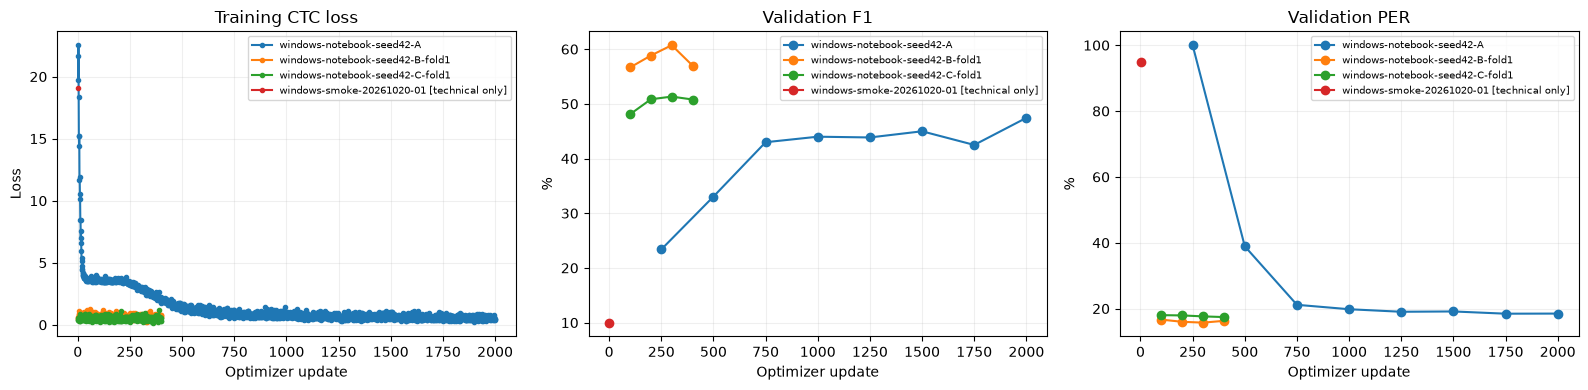

In [24]:
discovered_runs = app.status()["training"]
PLOT_RUN_IDS = list(RUN_IDS.values())
existing_smoke = next((row["run_id"] for row in discovered_runs if row["purpose"] == "technical_smoke_only"), None)
if existing_smoke:
    PLOT_RUN_IDS.append(existing_smoke)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plotted = 0
for run_id in PLOT_RUN_IDS:
    directory = ROOT / "runs" / run_id
    if not (directory / "training_log.jsonl").is_file():
        continue
    run_config = read_json(directory / "config.json")
    label = run_id + (" [technical only]" if run_config["purpose"] != "scientific_training" else "")
    history = pd.json_normalize(read_live_log(directory / "training_log.jsonl"))
    if history.empty:
        continue
    history.to_csv(OUT / f"history_{run_id.replace('/', '_')}.csv", index=False)
    axes[0].plot(history.step, history.loss, marker=".", label=label)
    if (directory / "validation_log.jsonl").is_file():
        validation = pd.json_normalize(read_live_log(directory / "validation_log.jsonl"))
        for ax, metric in zip(axes[1:], ["f1", "per"]):
            if not validation.empty:
                ax.plot(validation.step, 100*validation[f"metrics.{metric}"], marker="o", label=label)
    plotted += 1
for ax, title, ylabel in zip(axes, ["Training CTC loss", "Validation F1", "Validation PER"], ["Loss", "%", "%"]):
    ax.set(xlabel="Optimizer update", ylabel=ylabel, title=title)
    if ax.lines:
        ax.legend(fontsize=7)
if plotted:
    show_figure("learning_curves", fig)
else:
    plt.close(fig)
    print("Chưa có log cho các run đã chọn.")


## 25–27. Đánh giá test A, B và C (ba cell riêng)

`RUN_FINAL_TEST=True` đã được bật sau khi hoàn tất training và cố định best checkpoint bằng validation.
Cả A/B/C được đánh giá trên cùng fold, toàn bộ test, không giới hạn `--max-samples`.
Output test có đường dẫn cố định theo experiment; nếu đã tồn tại, cell giữ nguyên kết quả
để tránh chạy lại test. Chọn `EXPERIMENT` mới nếu chủ động làm một thí nghiệm khác.


In [25]:
# Đánh giá checkpoint A trên test của fold đã chọn.
if EVALUATIONS["A"].exists():
    if not all((EVALUATIONS["A"] / name).is_file() for name in ("metrics.json", "predictions.jsonl")):
        raise RuntimeError(f"Output test chưa hoàn tất: {EVALUATIONS['A']}. "
                           "Giữ log để kiểm tra; đổi EVALUATIONS của stage này sang một thư mục mới trước khi chạy lại.")
    print("Giữ kết quả test đã có:", EVALUATIONS["A"])
else:
    run_python("test_A", "-u", "scripts/evaluate_mdd.py", "--checkpoint", CHECKPOINTS["A"],
               "--split", "test", "--fold", FOLD, "--device", TRAIN_DEVICE,
               "--output-dir", EVALUATIONS["A"], execute=RUN_FINAL_TEST)


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' '-u' 'scripts/evaluate_mdd.py' '--checkpoint' 'D:\NCC\MDD\runs\windows-notebook-seed42-A\best_checkpoint' '--split' 'test' '--fold' '1' '--device' 'cuda' '--output-dir' 'D:\NCC\MDD\runs\windows-notebook-seed42-A-test-fold1'


{
  "precision": 0.6776669224865695,
  "recall": 0.6502209131075111,
  "f1": 0.6636602780909433,
  "far": 0.34977908689248893,
  "frr": 0.11023622047244094,
  "der": 0.35714285714285715,
  "per": 0.2139002805957263,
  "word_precision": 0.8573170731707317,
  "word_recall": 0.767467248908297,
  "word_f1": 0.8099078341013825
}
Log: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\test_A-05.log


In [26]:
# Đánh giá checkpoint B trên test của fold đã chọn.
if EVALUATIONS["B"].exists():
    if not all((EVALUATIONS["B"] / name).is_file() for name in ("metrics.json", "predictions.jsonl")):
        raise RuntimeError(f"Output test chưa hoàn tất: {EVALUATIONS['B']}. "
                           "Giữ log để kiểm tra; đổi EVALUATIONS của stage này sang một thư mục mới trước khi chạy lại.")
    print("Giữ kết quả test đã có:", EVALUATIONS["B"])
else:
    run_python("test_B", "-u", "scripts/evaluate_mdd.py", "--checkpoint", CHECKPOINTS["B"],
               "--split", "test", "--fold", FOLD, "--device", TRAIN_DEVICE,
               "--output-dir", EVALUATIONS["B"], execute=RUN_FINAL_TEST)


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' '-u' 'scripts/evaluate_mdd.py' '--checkpoint' 'D:\NCC\MDD\runs\windows-notebook-seed42-B-fold1\best_checkpoint' '--split' 'test' '--fold' '1' '--device' 'cuda' '--output-dir' 'D:\NCC\MDD\runs\windows-notebook-seed42-B-fold1-test-fold1'


{
  "precision": 0.7028985507246377,
  "recall": 0.7142857142857143,
  "f1": 0.7085463842220598,
  "far": 0.2857142857142857,
  "frr": 0.10786635096027361,
  "der": 0.347781217750258,
  "per": 0.192531836822793,
  "word_precision": 0.867579908675799,
  "word_recall": 0.8296943231441049,
  "word_f1": 0.8482142857142857
}
Log: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\test_B-06.log


In [27]:
# Đánh giá checkpoint C trên test của fold đã chọn.
if EVALUATIONS["C"].exists():
    if not all((EVALUATIONS["C"] / name).is_file() for name in ("metrics.json", "predictions.jsonl")):
        raise RuntimeError(f"Output test chưa hoàn tất: {EVALUATIONS['C']}. "
                           "Giữ log để kiểm tra; đổi EVALUATIONS của stage này sang một thư mục mới trước khi chạy lại.")
    print("Giữ kết quả test đã có:", EVALUATIONS["C"])
else:
    run_python("test_C", "-u", "scripts/evaluate_mdd.py", "--checkpoint", CHECKPOINTS["C"],
               "--split", "test", "--fold", FOLD, "--device", TRAIN_DEVICE,
               "--output-dir", EVALUATIONS["C"], execute=RUN_FINAL_TEST)


& 'D:\NCC\MDD\.venv\Scripts\python.exe' '-X' 'utf8' '-u' 'scripts/evaluate_mdd.py' '--checkpoint' 'D:\NCC\MDD\runs\windows-notebook-seed42-C-fold1\best_checkpoint' '--split' 'test' '--fold' '1' '--device' 'cuda' '--output-dir' 'D:\NCC\MDD\runs\windows-notebook-seed42-C-fold1-test-fold1'


{
  "precision": 0.6726703210649961,
  "recall": 0.6325478645066274,
  "f1": 0.6519924098671727,
  "far": 0.36745213549337263,
  "frr": 0.11008691071898867,
  "der": 0.3787878787878788,
  "per": 0.21994388085473776,
  "word_precision": 0.8620253164556962,
  "word_recall": 0.7434497816593887,
  "word_f1": 0.798358733880422
}
Log: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z\test_C-07.log


## 28. Kiểm chứng phép so sánh A/B/C

Chỉ đọc kết quả thật. Verifier tính lại counters từ prediction/gold, kiểm tra checksum,
cùng fold/audio/gold, training hoàn tất, weights A khởi tạo B/C và ngân sách B/C tương ứng.
Nếu thiếu kết quả thì báo thiếu; nếu sai điều kiện thì dừng. Không bỏ qua kiểm chứng để vẽ.
JSON/CSV của phép so sánh được lưu vào output session hiện tại.


In [28]:
from scripts.compare_mdd_runs import compare_runs

comparison = None
missing = [stage for stage, directory in EVALUATIONS.items()
           if not (directory / "metrics.json").is_file() or not (directory / "predictions.jsonl").is_file()]
if missing:
    print("Chưa có đủ test khoa học. Thiếu:", ", ".join(missing))
    print("Chạy A/B/C và các cell test tương ứng; smoke không dùng cho bảng so sánh này.")
else:
    attempt = OUT / "comparison" / datetime.now(timezone.utc).strftime("%H%M%S%f")
    comparison = compare_runs(EVALUATIONS["A"], EVALUATIONS["B"], EVALUATIONS["C"], attempt)
    print("Đã xác minh", comparison["utterance_count"], "audio ghép cặp, fold", comparison["fold"])
    print(json.dumps(comparison["verification"], indent=2))


Đã xác minh 150 audio ghép cặp, fold 1
{
  "paired_ids_audio_and_gold": true,
  "full_test_evaluations": true,
  "all_phone_and_word_counts_recomputed": true,
  "prediction_file_hashes_verified": true,
  "same_stage_A_initialization_weights": true,
  "matched_B_C_completed_optimizer_step_budget_and_configuration": true
}


## 29. Visualization kết quả test và mức thay đổi

F1/precision/recall càng cao càng tốt; FAR/FRR/DER/PER càng thấp càng tốt.
Metric vẽ theo %. B−A và B−C đã có đơn vị **điểm phần trăm**, không nhân 100 lần nữa.
PER có thể vượt 100% nếu nhiều insertion. Giá trị không xác định giữ là NaN.
Một fold không đủ để suy ra độ tin cậy thống kê hoặc toàn bộ người Việt.


,metric,A,B,C
0,precision,67.766692,70.289855,67.267032
1,recall,65.022091,71.428571,63.254786
2,f1,66.366028,70.854638,65.199241
3,far,34.977909,28.571429,36.745214
4,frr,11.023622,10.786635,11.008691
5,der,35.714286,34.778122,37.878788
6,per,21.390028,19.253184,21.994388
7,word_precision,85.731707,86.757991,86.202532
8,word_recall,76.746725,82.969432,74.344978
9,word_f1,80.990783,84.821429,79.835873


,metric,better,B_minus_A_percentage_points,B_minus_C_percentage_points
0,precision,higher,2.523163,3.022823
1,recall,higher,6.40648,8.173785
2,f1,higher,4.488611,5.655397
3,far,lower,-6.40648,-8.173785
4,frr,lower,-0.236987,-0.222056
5,der,lower,-0.936164,-3.100666
6,per,lower,-2.136844,-2.741204
7,word_precision,higher,1.026284,0.555459
8,word_recall,higher,6.222707,8.624454
9,word_f1,higher,3.830645,4.985555


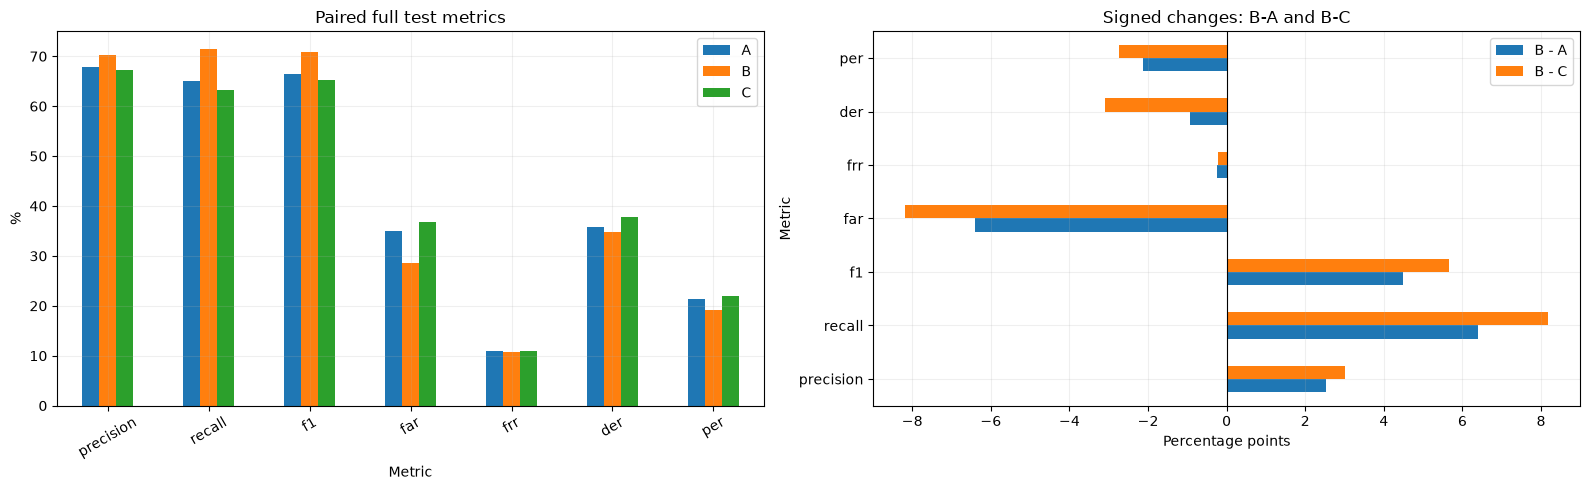

In [29]:
if comparison is not None:
    metrics = ["precision", "recall", "f1", "far", "frr", "der", "per"]
    metric_table = pd.DataFrame({stage: comparison["runs"][stage]["metrics"] for stage in ("A", "B", "C")})
    save_table("test_metrics_percent", (metric_table * 100).rename_axis("metric").reset_index())
    deltas = pd.DataFrame(comparison["differences"]).T
    save_table("test_deltas_percentage_points", deltas.rename_axis("metric").reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    (metric_table.loc[metrics] * 100).plot.bar(ax=axes[0], rot=30)
    axes[0].set(title="Paired full test metrics", ylabel="%", xlabel="Metric")
    delta_columns = ["B_minus_A_percentage_points", "B_minus_C_percentage_points"]
    deltas.loc[metrics, delta_columns].astype(float).plot.barh(ax=axes[1])
    axes[1].axvline(0, color="black", linewidth=0.8)
    axes[1].set(title="Signed changes: B-A and B-C", xlabel="Percentage points", ylabel="Metric")
    axes[1].legend(handles=axes[1].containers[:2], labels=["B - A", "B - C"])
    show_figure("paired_test_comparison", fig)
else:
    print("Biểu đồ sẽ xuất hiện khi cell 28 kiểm chứng thành công đủ kết quả A/B/C.")


## 30. Phân tích lỗi từ prediction đã kiểm chứng

Heatmap tổng hợp thay thế phone khi căn chỉnh **gold perceived → predicted**, không phải
ma trận phân loại lỗi trực tiếp của model. Bảng TR/FA/FR/TA là counters theo scorer của dự án.
Giữ cách xử lý insertion và normalization của scorer; không tự tính một định nghĩa F1 khác.


,counter,A,B,C
0,TR,883,970,859
1,FA,475,388,499
2,FR,420,410,418
3,TA,3390,3391,3379
4,CD,567,632,533
5,DE,315,337,325


,gold,predicted,count
0,Z,S,48
1,IY,IH,44
2,AO,AH,20
3,IH,IY,20
4,EH,AE,17
5,T,D,13
6,B,P,12
7,S,Z,11
8,AO,OW,11
9,IH,UW,10


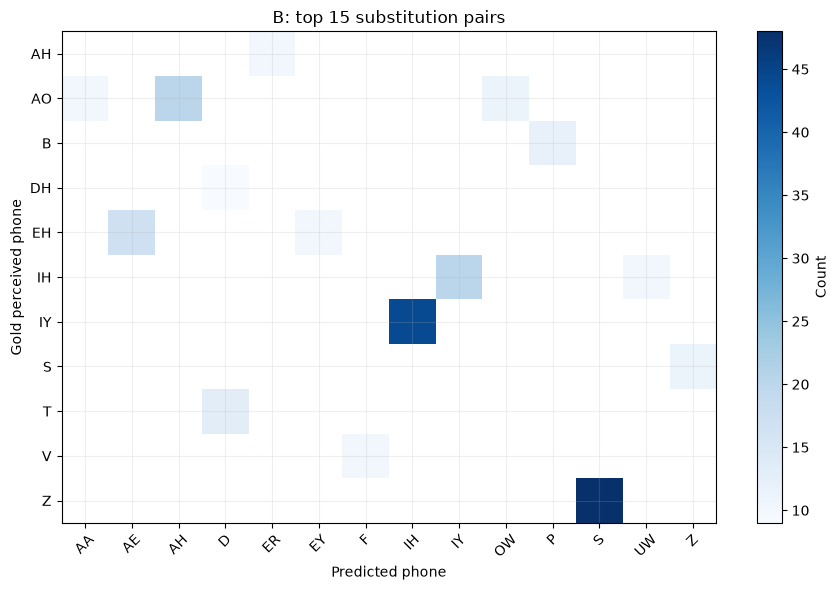

In [30]:
from collections import Counter

if comparison is not None:
    rows = read_jsonl(EVALUATIONS["B"] / "predictions.jsonl")
    confusions = Counter()
    for row in rows:
        for event in align_phones(row["perceived_phones"], row["predicted_phones"]):
            if event["kind"] == "substitution":
                confusions[(event["expected_phone"], event["observed_phone"])] += 1
    counter_table = pd.DataFrame({stage: comparison["runs"][stage]["counts"] for stage in ("A", "B", "C")})
    save_table("test_detection_counts", counter_table.loc[["TR", "FA", "FR", "TA", "CD", "DE"]].rename_axis("counter").reset_index())
    if confusions:
        top = confusions.most_common(15)
        confusion_table = pd.DataFrame([{"gold": pair[0], "predicted": pair[1], "count": count} for pair, count in top])
        save_table("B_top_substitutions", confusion_table)
        # Blank cells are pairs outside this top-15 selection, not zero-count claims.
        matrix = confusion_table.pivot(index="gold", columns="predicted", values="count")
        fig, ax = plt.subplots(figsize=(9, 6))
        im = ax.imshow(matrix.to_numpy(), cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45)
        ax.set_yticks(range(len(matrix.index)), matrix.index)
        ax.set(xlabel="Predicted phone", ylabel="Gold perceived phone", title="B: top 15 substitution pairs")
        fig.colorbar(im, ax=ax, label="Count")
        show_figure("B_phone_substitutions", fig)
    else:
        print("Không có substitution; xem counters cho deletion/insertion.")
else:
    print("Chưa có prediction test đã kiểm chứng để phân tích lỗi A/B/C.")


## 31. Lưu và chia sẻ kết quả

Cell cuối tạo danh sách artifact và thông tin phiên. **Ctrl+S** lưu notebook kèm biểu đồ/output.
Có thể xuất HTML (bao gồm audio mẫu được nhúng) hoặc chạy toàn bộ chế độ demo bằng lệnh:

```powershell
& .\.venv\Scripts\python.exe -m jupyter nbconvert --to html notebooks/mdd_local_demo_comparison.ipynb --output-dir data/generated/notebook
& .\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute notebooks/mdd_local_demo_comparison.ipynb --ExecutePreprocessor.kernel_name=mdd-local --ExecutePreprocessor.timeout=900 --output mdd_local_demo_executed.ipynb --output-dir data/generated/notebook
```

Chạy cả 4 fold bằng cách đổi `FOLD` rồi train B/C và test từng fold, luôn giữ cùng A.
Các fold dùng lại một số người nói trong vai trò khác nhau; không coi câu hoặc fold là
quan sát thống kê độc lập. Notebook không tự kết luận significance.
Demo giao diện web riêng: `pwsh -File scripts/run_demo.ps1`, mở `http://127.0.0.1:8765`.


In [31]:
save_json("session", {"session_utc": SESSION, "python": sys.executable, "fold": FOLD, "seed": SEED,
                      "train_device": TRAIN_DEVICE, "run_ids": RUN_IDS, "sample_id": sample_id,
                      "scientific_comparison_available": comparison is not None,
                      "notebook": "notebooks/mdd_local_demo_comparison.ipynb"})
artifacts = []
for path in sorted(OUT.rglob("*")):
    if path.is_file() and path != OUT / "artifacts.json":
        artifacts.append({"file": path.relative_to(OUT).as_posix(), "bytes": path.stat().st_size,
                          "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
save_json("artifacts", artifacts)
display(pd.DataFrame(artifacts)[["file", "bytes"]])
print("Kết quả phiên:", OUT)
print("Lưu notebook bằng Ctrl+S để giữ các output vừa chạy.")


Kết quả phiên: D:\NCC\MDD\data\generated\notebook\20261020T153902638631Z
Lưu notebook bằng Ctrl+S để giữ các output vừa chạy.


,file,bytes
0,audio_waveform_spectrogram.png,357059
1,B_phone_substitutions.png,43763
2,B_top_substitutions.csv,163
3,base_inference.json,3651
4,commands.json,3295
5,comparison/154120221636/comparison.csv,19518
6,comparison/154120221636/summary.json,52646
7,contracts-04.log,153
8,dataset_by_language.csv,242
9,dataset_overview.png,76706


## 32. Demo hướng dẫn tiếng Việt & giọng mẫu tiếng Anh (LLM + ai33)

Mở giao diện với **best checkpoint B** từ thí nghiệm đã hoàn tất. Demo đối chiếu
âm thanh trên máy, chỉ rõ khác biệt âm vị theo từng từ, rồi tạo hướng dẫn tiếng
Việt và giọng đọc mẫu tiếng Anh. Phần này không chạy lại training hay các phép
so sánh khoa học phía trên.

Chạy server trong terminal: `pwsh -File scripts/run_demo.ps1`. Điền khóa của bạn
vào file `.env` ở thư mục project và khởi động lại server khi thay đổi cấu hình.
**Không dán khóa vào notebook, không in nội dung `.env` và không lưu khóa trong output.**
Cell trạng thái dưới đây chỉ đọc các cờ khả dụng công khai, không đọc file chứa khóa.

`RUN_ONLINE_GUIDANCE=False` là mặc định: chỉ xem **kết quả thật đã lưu** trong
`data/generated/demo`, không gửi POST phân tích/hướng dẫn và không tạo giọng đọc mới.
Mã phân tích phải khớp giữa kết quả, hướng dẫn và bản kiểm tra; file audio được
kiểm SHA-256 trước khi nhúng. Đây là bản ghi demo đã chạy, không phải một lượt gọi mới. Đổi thành `True` rồi chạy lần lượt các cell mới khi bạn muốn
thử dịch vụ thật; yêu cầu LLM và ai33 **có thể phát sinh phí** trên tài khoản của bạn.
Âm thanh được xử lý local; câu tham chiếu/kết quả âm vị được gửi tới LLM và nội dung
cần đọc được gửi tới ai33. Giọng đọc chỉ phát khi bạn nhấn nút Play.

Nếu dịch vụ chưa được kết nối, bảng lỗi từ mô hình vẫn có thể hiển thị; nguồn
`template` là hướng dẫn mẫu, không được trình bày như phản hồi LLM thành công.
Trong giao diện, chọn BASE trước fine-tune (chỉ đặc trưng), A trước thích ứng giọng Việt, hoặc B sau thích ứng. Để so sánh nhận diện lỗi trước/sau thích ứng, dùng A và B trên cùng bản thu. Kết quả MDD hiện ngay sau suy luận CPU; ba ô tiến độ báo MDD đã xong, LLM đang tạo hướng dẫn, rồi ai33 đang tạo giọng đọc. Hướng dẫn LLM hiện trước khi audio hoàn tất.


In [32]:
# Cấu hình độc lập cho phần demo; không đọc .env và không đổi cờ training.
import json as _demo_json
import hashlib as _demo_hashlib
from pathlib import Path as _DemoPath
from urllib import error as _demo_error, parse as _demo_parse, request as _demo_http
import pandas as pd
from IPython.display import Audio, display

RUN_ONLINE_GUIDANCE = False  # False: đọc kết quả thật đã lưu; True: có thể gọi dịch vụ tính phí.
_DEMO_ROOT = next((candidate for candidate in (_DemoPath.cwd(), *_DemoPath.cwd().parents)
                   if (candidate / "src/mdd/runtime.py").is_file()), None)
if _DEMO_ROOT is None:
    raise RuntimeError("Mở notebook trong thư mục project để tìm kết quả demo đã lưu.")
DEMO_CACHE_DIR = _DEMO_ROOT / "data/generated/demo"
DEMO_BASE_URL = "http://127.0.0.1:8765"
DEMO_BEST_B_RUN_ID = globals().get("RUN_IDS", {}).get("B", "windows-notebook-seed42-B-fold1")
DEMO_MODEL_ID = f"run:{DEMO_BEST_B_RUN_ID}:best"
DEMO_SAMPLE_ID = None  # Có thể điền id mẫu từ /api/prompts; None chọn mẫu hiện có/đầu tiên.
DEMO_GUIDANCE_URL = f"{DEMO_BASE_URL}/?model={_demo_parse.quote(DEMO_MODEL_ID, safe='')}"
_demo_base = _demo_parse.urlsplit(DEMO_BASE_URL)
if _demo_base.scheme != "http" or _demo_base.hostname not in {"127.0.0.1", "localhost", "::1"} or _demo_base.username or _demo_base.password:
    raise ValueError("DEMO_BASE_URL cần là địa chỉ HTTP loopback của server local.")
_demo_opener = _demo_http.build_opener(_demo_http.ProxyHandler({}))

def _demo_request(path, payload=None, timeout=15):
    if not path.startswith("/api/") or path.startswith("//"):
        raise ValueError("Chỉ gọi API local của demo.")
    data = None if payload is None else _demo_json.dumps(payload).encode("utf-8")
    request = _demo_http.Request(DEMO_BASE_URL.rstrip("/") + path, data=data,
                                 headers={"Content-Type": "application/json"} if data is not None else {},
                                 method="GET" if data is None else "POST")
    try:
        with _demo_opener.open(request, timeout=timeout) as response:
            return _demo_json.load(response)
    except _demo_error.HTTPError as error:
        raise RuntimeError(f"API demo local trả về HTTP {error.code}; xem trạng thái trên giao diện.") from None
    except _demo_error.URLError:
        raise RuntimeError("Chưa kết nối được demo local; chạy run_demo.ps1 và kiểm tra cổng.") from None

_demo_status = None
_demo_analysis = None
_demo_feedback = None
_demo_cache_summary = None
print("Giao diện best B:", DEMO_GUIDANCE_URL)
print("Gọi dịch vụ có thể tính phí:", RUN_ONLINE_GUIDANCE)
print("Chế độ:", "Gọi mới có thể tính phí" if RUN_ONLINE_GUIDANCE else "Xem bản ghi demo thật đã lưu; không gửi POST")


Giao diện best B: http://127.0.0.1:8765/?model=run%3Awindows-notebook-seed42-B-fold1%3Abest
Gọi dịch vụ có thể tính phí: False
Chế độ: Xem bản ghi demo thật đã lưu; không gửi POST


In [33]:
# Chỉ GET trạng thái công khai; không gửi audio, không đọc hay hiển thị khóa.
try:
    _demo_status = _demo_request("/api/status", timeout=15)
except RuntimeError as error:
    print(error)
else:
    _demo_models = _demo_status.get("models", [])
    display(pd.DataFrame([{key: model.get(key) for key in
                          ("id", "label", "kind", "ready", "experimental", "step")}
                         for model in _demo_models]))
    _demo_caps = _demo_status.get("capabilities", {})
    _demo_public_flags = ("llm_configured", "tts_configured", "english_voice_configured", "vietnamese_voice_configured")
    display(pd.DataFrame([{"khả_năng": key, "sẵn_sàng": bool(_demo_caps.get(key, False))}
                          for key in _demo_public_flags]))
    print("Chỉ đọc trạng thái. Chưa gửi yêu cầu LLM hoặc tạo giọng đọc.")

Chỉ đọc trạng thái. Chưa gửi yêu cầu LLM hoặc tạo giọng đọc.


,id,label,kind,ready,experimental,step
0,base,wav2vec 2.0 BASE,backbone,True,False,NaN
1,run:windows-notebook-seed42-A:best,windows-notebook-seed42-A · best,phoneme,True,False,2000.0
2,run:windows-notebook-seed42-A:latest,windows-notebook-seed42-A · latest,phoneme,True,False,2000.0
3,run:windows-notebook-seed42-B-fold1:best,windows-notebook-seed42-B-fold1 · best,phoneme,True,False,300.0
4,run:windows-notebook-seed42-B-fold1:latest,windows-notebook-seed42-B-fold1 · latest,phoneme,True,False,400.0
5,run:windows-notebook-seed42-C-fold1:best,windows-notebook-seed42-C-fold1 · best,phoneme,True,False,300.0
6,run:windows-notebook-seed42-C-fold1:latest,windows-notebook-seed42-C-fold1 · latest,phoneme,True,False,400.0
7,run:windows-smoke-20261020-01:best,windows-smoke-20261020-01 · best,phoneme,True,True,1.0
8,run:windows-smoke-20261020-01:latest,windows-smoke-20261020-01 · latest,phoneme,True,True,1.0


,khả_năng,sẵn_sàng
0,llm_configured,True
1,tts_configured,True
2,english_voice_configured,True
3,vietnamese_voice_configured,True


In [34]:
# Khi bật opt-in: phân tích một mẫu bằng best B, vẫn dùng CPU inference local.
_demo_analysis = None
_demo_feedback = None
if not RUN_ONLINE_GUIDANCE:
    _demo_cached_analysis_path = DEMO_CACHE_DIR / "live-analysis.json"
    if _demo_cached_analysis_path.is_file():
        _demo_cached_analysis = _demo_json.loads(_demo_cached_analysis_path.read_text(encoding="utf-8"))
        _demo_cached_model = _demo_cached_analysis.get("model_id") or (_demo_cached_analysis.get("model") or {}).get("id")
        if not _demo_cached_analysis.get("analysis_id") or _demo_cached_model != DEMO_MODEL_ID:
            raise RuntimeError("Bản phân tích đã lưu chưa khớp best B được chọn; không tự thay bằng dữ liệu khác.")
        _demo_analysis = _demo_cached_analysis
        print("Đang xem kết quả MDD thật đã lưu từ live-analysis.json; không suy luận/gọi dịch vụ mới.")
        print("Câu tham chiếu:", _demo_analysis.get("reference_text", ""))
    else:
        print("Chưa có bản phân tích đã lưu. Không POST /api/analyze; không gọi LLM/ai33.")
else:
    _demo_current_status = _demo_request("/api/status", timeout=15)
    _demo_model = next((model for model in _demo_current_status.get("models", [])
                        if model.get("id") == DEMO_MODEL_ID), None)
    if not _demo_model or _demo_model.get("ready") is False or _demo_model.get("kind") != "phoneme" or _demo_model.get("experimental"):
        raise RuntimeError("Best B khoa học chưa sẵn sàng; kiểm tra checkpoint và model đã chọn.")
    _demo_prompts = _demo_request("/api/prompts", timeout=15).get("prompts", [])
    if not _demo_prompts:
        raise RuntimeError("Server chưa có mẫu để demo.")
    _demo_selected_id = DEMO_SAMPLE_ID or globals().get("sample_id")
    _demo_sample = next((sample for sample in _demo_prompts if sample.get("id") == _demo_selected_id), None)
    if DEMO_SAMPLE_ID and _demo_sample is None:
        raise ValueError("DEMO_SAMPLE_ID không nằm trong danh sách mẫu của server.")
    _demo_sample = _demo_sample or _demo_prompts[0]
    print("Mẫu:", _demo_sample["id"], "| Câu:", _demo_sample["text"])
    _demo_analysis = _demo_request("/api/analyze", {
        "model_id": DEMO_MODEL_ID,
        "sample_id": _demo_sample["id"],
        "reference_text": _demo_sample["text"],
    }, timeout=120)
    print("MDD local hoàn tất. Có thể tạo hướng dẫn:", bool(_demo_analysis.get("feedback_available")))
    if _demo_analysis.get("feedback_available") is False:
        print(_demo_analysis.get("feedback_unavailable_reason", "Chưa đủ dữ liệu đối chiếu để tạo hướng dẫn."))

Đang xem kết quả MDD thật đã lưu từ live-analysis.json; không suy luận/gọi dịch vụ mới.
Câu tham chiếu: She added with genuine sympathy in her face and voice


In [35]:
# False chỉ đọc phản hồi đã lưu cùng mã phân tích; True mới gửi yêu cầu dịch vụ.
_demo_feedback = None
if not RUN_ONLINE_GUIDANCE:
    _demo_cached_feedback_path = DEMO_CACHE_DIR / "live-feedback.json"
    if _demo_analysis and _demo_cached_feedback_path.is_file():
        _demo_candidate = _demo_json.loads(_demo_cached_feedback_path.read_text(encoding="utf-8"))
        if _demo_candidate.get("analysis_id") != _demo_analysis["analysis_id"]:
            raise RuntimeError("Phản hồi đã lưu thuộc một mã phân tích khác; không ghép các lượt demo.")
        if _demo_candidate.get("feedback_source") not in {"llm", "template"}:
            raise RuntimeError("Bản phản hồi thiếu nguồn dữ liệu hợp lệ; không tự gán là LLM.")
        _demo_feedback = _demo_candidate
        print("Đang xem hướng dẫn thật đã lưu từ live-feedback.json; không POST /api/feedback.")
    else:
        print("Chưa có phản hồi đã lưu cùng lượt phân tích; không phát sinh yêu cầu LLM/ai33.")
elif not _demo_analysis:
    print("Chạy cell phân tích local phía trên trước.")
elif _demo_analysis.get("feedback_available") is False or not _demo_analysis.get("analysis_id"):
    print("Hướng dẫn chưa khả dụng; bảng đối chiếu local vẫn có thể xem ở cell tiếp theo.")
else:
    _demo_feedback = _demo_request("/api/feedback", {
        "analysis_id": _demo_analysis["analysis_id"],
        "include_voice": True,
    }, timeout=900)
    if _demo_feedback.get("analysis_id") != _demo_analysis["analysis_id"]:
        raise RuntimeError("Hướng dẫn không khớp mã phân tích hiện tại.")
if _demo_feedback:
    print("Trạng thái:", _demo_feedback.get("status"), "| Nguồn thực tế:", _demo_feedback.get("feedback_source"),
          "| Giọng đọc:", _demo_feedback.get("voice_status"))
    for _demo_notice in _demo_feedback.get("notices", []):
        print(_demo_notice)


Đang xem hướng dẫn thật đã lưu từ live-feedback.json; không POST /api/feedback.
Trạng thái: ready | Nguồn thực tế: llm | Giọng đọc: ready
Sai khác âm vị do model ước lượng; hướng dẫn chưa thay thế đánh giá của giáo viên.


In [36]:
# Bảng theo vị trí từ; không tạo mốc thời gian/độ tin cậy khi server không cung cấp.
_demo_assessment = ((_demo_feedback or {}).get("assessment") or
                    (_demo_analysis or {}).get("assessment") or {})
_demo_words = {word["index"]: word.get("text", "") for word in _demo_assessment.get("words", [])}
_demo_error_rows = []
for _demo_error_row in _demo_assessment.get("errors", []):
    _demo_word_index = _demo_error_row.get("word_index")
    _demo_error_rows.append({
        "error_id": _demo_error_row.get("id"),
        "vị_trí_từ": _demo_word_index + 1 if isinstance(_demo_word_index, int) and _demo_word_index >= 0 else None,
        "từ": _demo_words.get(_demo_word_index, "Chưa xác định"),
        "loại": _demo_error_row.get("type"),
        "âm_mục_tiêu": _demo_error_row.get("expected_ipa") or _demo_error_row.get("expected_phone") or "∅",
        "âm_nhận_diện": _demo_error_row.get("observed_ipa") or _demo_error_row.get("observed_phone") or "∅",
        "bắt_đầu_giây": _demo_error_row.get("start_sec"),
        "kết_thúc_giây": _demo_error_row.get("end_sec"),
        "độ_tin_cậy": _demo_error_row.get("confidence"),
    })
demo_errors_df = pd.DataFrame(_demo_error_rows, columns=["error_id", "vị_trí_từ", "từ", "loại", "âm_mục_tiêu", "âm_nhận_diện", "bắt_đầu_giây", "kết_thúc_giây", "độ_tin_cậy"])
_demo_feedback_text = (_demo_feedback or {}).get("feedback") or {}
demo_tips_df = pd.DataFrame([{
    "error_id": tip.get("error_id"), "giải_thích": tip.get("explanation"),
    "cách_luyện": tip.get("instruction"), "từ_luyện_tập": " · ".join(tip.get("practice_words") or []),
} for tip in _demo_feedback_text.get("tips", [])], columns=["error_id", "giải_thích", "cách_luyện", "từ_luyện_tập"])
if _demo_analysis or _demo_feedback:
    display(demo_errors_df)
    display(demo_tips_df)
    if _demo_feedback_text.get("summary"):
        print(_demo_feedback_text["summary"])
else:
    print("Chưa gọi demo online; chưa có bảng lỗi/hướng dẫn mới. Kết quả khoa học phía trên được giữ nguyên.")

Hệ thống phát hiện một số khác biệt ở từ "genuine", "and" và "voice" so với phiên âm chuẩn; xem chi tiết từng lỗi bên dưới.


,error_id,vị_trí_từ,từ,loại,âm_mục_tiêu,âm_nhận_diện,bắt_đầu_giây,kết_thúc_giây,độ_tin_cậy
0,e1,4,genuine,addition,∅,d,None,None,None
1,e2,4,genuine,deletion,AH,∅,None,None,None
2,e3,4,genuine,substitution,w,u,None,None,None
3,e4,9,and,deletion,d,∅,None,None,None
4,e5,10,voice,deletion,v,∅,None,None,None


,error_id,giải_thích,cách_luyện,từ_luyện_tập
0,e1,"Mô hình ghi nhận âm /d/ thừa xuất hiện ở từ ""g...","Đọc ""genuine"" liền mạch, không chèn thêm âm /d...",genuine · genius · genuinely
1,e2,"Hệ thống ghi nhận âm AH bị thiếu trong từ ""gen...","Giữ nguyên âm giữa, miệng mở nhẹ để phát âm AH...",genuine · continue
2,e3,Model ghi nhận âm /w/ bị thay bằng /u/ trong t...,Tròn môi nhẹ rồi bật nhanh sang nguyên âm tiếp...,genuine · wet · way
3,e4,"Hệ thống ghi nhận âm /d/ cuối từ ""and"" (vị trí...",Chạm đầu lưỡi vào lợi trên để kết thúc bằng /d...,and · band · sand
4,e5,"Hệ thống ghi nhận âm /v/ đầu từ ""voice"" (vị tr...","Chạm nhẹ răng trên vào môi dưới, đẩy hơi rung ...",voice · very · victory


In [37]:
# False: chỉ file local khớp manifest + SHA-256. True: /api/voice/ cùng origin.
_demo_audio_mimes = {"audio/mpeg", "audio/mp3", "audio/wav", "audio/x-wav", "audio/ogg", "audio/webm", "audio/mp4", "audio/aac", "audio/flac", "audio/x-flac"}

def _demo_display_voice(clip, data, mime):
    if mime not in _demo_audio_mimes:
        raise RuntimeError("Content-Type của giọng đọc không phải định dạng audio được hỗ trợ.")
    language, purpose = clip.get("language", ""), clip.get("purpose", "")
    print("Hướng dẫn tiếng Việt" if language.startswith("vi") else
          "Luyện từ tiếng Anh" if purpose == "practice" else "Câu mẫu tiếng Anh")
    print(clip.get("text", ""))
    player = Audio(data=data, autoplay=False)
    player.mimetype = mime
    display(player)

_demo_audio_count = 0
if not _demo_feedback:
    print("Chưa có phản hồi cùng mã phân tích; không tải giọng đọc.")
elif not RUN_ONLINE_GUIDANCE:
    _demo_manifest_path = DEMO_CACHE_DIR / "guidance-check.json"
    if not _demo_manifest_path.is_file():
        print("Chưa có bản kiểm tra audio đã lưu; không tải hoặc tạo giọng đọc mới.")
    else:
        _demo_cache_summary = _demo_json.loads(_demo_manifest_path.read_text(encoding="utf-8"))
        if (_demo_cache_summary.get("analysis_id") != _demo_analysis["analysis_id"]
                or _demo_cache_summary.get("analysis_id") != _demo_feedback["analysis_id"]
                or _demo_cache_summary.get("model_id") != DEMO_MODEL_ID
                or _demo_cache_summary.get("source") != _demo_feedback["feedback_source"]):
            raise RuntimeError("Bản kiểm tra audio không khớp lượt phân tích/model/nguồn phản hồi đã lưu.")
        print("Giọng đọc thật đã lưu; kiểm SHA-256 trước khi nhúng. Không gọi mạng để tải audio.")
        for _demo_clip in _demo_feedback.get("audio", []):
            if _demo_clip.get("status") != "ready":
                print(_demo_clip.get("message", "Một giọng đọc chưa sẵn sàng."))
                continue
            _demo_records = [record for record in _demo_cache_summary.get("audio", [])
                             if record.get("status") == "ready" and record.get("language") == _demo_clip.get("language")
                             and record.get("purpose") == _demo_clip.get("purpose")]
            if len(_demo_records) != 1:
                raise RuntimeError("Không tìm thấy duy nhất một file audio đã kiểm tra cho đoạn giọng đọc.")
            _demo_record = _demo_records[0]
            _demo_relative_voice = _DemoPath(_demo_record.get("file", ""))
            _demo_local_voice = (_DEMO_ROOT / _demo_relative_voice).resolve()
            if (_demo_relative_voice.is_absolute() or not _demo_local_voice.is_relative_to(DEMO_CACHE_DIR.resolve())
                    or not _demo_local_voice.is_file()):
                raise RuntimeError("File giọng đọc phải nằm trong thư mục cache demo local.")
            _demo_voice_bytes = _demo_local_voice.read_bytes()
            if _demo_hashlib.sha256(_demo_voice_bytes).hexdigest() != _demo_record.get("sha256"):
                raise RuntimeError("SHA-256 audio khác bản kiểm tra; dừng nhúng để tránh dùng sai dữ liệu.")
            if _demo_record.get("bytes") is not None and len(_demo_voice_bytes) != _demo_record["bytes"]:
                raise RuntimeError("Kích thước audio khác bản kiểm tra.")
            _demo_display_voice(_demo_clip, _demo_voice_bytes, _demo_record.get("mime"))
            _demo_audio_count += 1
else:
    for _demo_clip in _demo_feedback.get("audio", []):
        if _demo_clip.get("status") != "ready":
            print(_demo_clip.get("message", "Một giọng đọc chưa sẵn sàng."))
            continue
        _demo_voice_url = _demo_parse.urljoin(DEMO_BASE_URL.rstrip("/") + "/", _demo_clip.get("url") or "")
        _demo_voice = _demo_parse.urlsplit(_demo_voice_url)
        if ((_demo_voice.scheme, _demo_voice.hostname, _demo_voice.port) !=
                (_demo_base.scheme, _demo_base.hostname, _demo_base.port)
                or not _demo_voice.path.startswith("/api/voice/") or _demo_voice.path == "/api/voice/"
                or _demo_voice.username or _demo_voice.password):
            print("Bỏ qua đường dẫn audio không thuộc API giọng đọc local.")
            continue
        with _demo_opener.open(_demo_voice_url, timeout=60) as _demo_voice_response:
            _demo_voice_mime = _demo_voice_response.headers.get_content_type()
            _demo_voice_bytes = _demo_voice_response.read()
        _demo_display_voice(_demo_clip, _demo_voice_bytes, _demo_voice_mime)
        _demo_audio_count += 1
if _demo_feedback and not _demo_audio_count:
    print("Chưa có giọng đọc đã kiểm tra. Có thể tiếp tục xem hướng dẫn bằng chữ.")


Giọng đọc thật đã lưu; kiểm SHA-256 trước khi nhúng. Không gọi mạng để tải audio.
Hướng dẫn tiếng Việt
Bạn cần chú ý ba từ: "genuine" phát âm rõ từng âm, không thêm hay bớt âm; "and" đọc đủ âm cuối dù trong câu nối âm có thể giảm nhẹ; "voice" phát âm rõ âm đầu bằng cách chạm răng vào môi dưới. Hãy luyện đọc lại các từ này rồi đọc cả câu.
Câu mẫu tiếng Anh
She added with genuine sympathy in her face and voice
Luyện từ tiếng Anh
genuine. and. voice.
